# Importaciones

In [ ]:
import pandas as pd
import numpy as np
from collections import Counter
import emoji
import html
import re
from itertools import combinations
import ipywidgets as widgets
from IPython.display import display
import unicodedata
import logging
from pathlib import Path
import os
import math
import urllib.request
import itertools

# Embedkit
from embedkit import EmbedKitAnalyzer
from embedkit import EmbedKit

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import umap

# Auxiliares
import torch

# Sentence Transformers
from sentence_transformers import SentenceTransformer

# Texto
import spacy
from nltk.util import ngrams
from nltk.util import skipgrams
from wordcloud import WordCloud
import fasttext

# Grafos
import networkx as nx

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Carga dataset

In [37]:
df = pd.read_parquet("../Datasets/consolidado_rmhd.parquet")
df

,author,created_utc,score,selftext,subreddit,title,timestamp,year,month,dataset_type
0,tcarrollsmit,1567259968,21,Anyone here have IBS due to anxiety? Have you ...,Anxiety,IBS &amp; anxiety,2019-08-31 23:59:28,2019,aug,anxiety
1,Jane_Meki_Jane,1567258811,1,I was just browsing in a store avoiding the em...,Anxiety,Was gonna get what I thought I needed but turn...,2019-08-31 23:40:11,2019,aug,anxiety
2,G-Random20,1567258607,1,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:36:47,2019,aug,anxiety
3,mimiforu,1567258357,1,It always seems like the hardest stuff happens...,Anxiety,I suffer from panic disorder and weekends seem...,2019-08-31 23:32:37,2019,aug,anxiety
4,G-Random20,1567257982,1,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:26:22,2019,aug,anxiety
...,...,...,...,...,...,...,...,...,...,...
1851575,username1627,1651328267,1,"Whenever I see comments such as ""it will get b...",SuicideWatch,Useless Rant,2022-05-01 00:17:47,2022,may,suicidewatch
1851576,verycoolusername231,1651327988,1,What even is the purpose in life? Nothing. Lif...,SuicideWatch,There is nothing.,2022-05-01 00:13:08,2022,may,suicidewatch
1851577,mogana_sunset,1651327849,1,[removed],SuicideWatch,"Why am I still here, just to suffer?",2022-05-01 00:10:49,2022,may,suicidewatch
1851578,uaipqwhy,1651327604,1,2? Idk if I gonna or not do it. \nBut I hope I do,SuicideWatch,countdown,2022-05-01 00:06:44,2022,may,suicidewatch


In [38]:
df.columns

Index(['author', 'created_utc', 'score', 'selftext', 'subreddit', 'title',
       'timestamp', 'year', 'month', 'dataset_type'],
      dtype='str')

Teniendo en cuenta el alcance y objetivos de la investigación, se filtran únicamente las variables y subreddits de interés.

In [39]:
df.drop(columns=["author","score", "created_utc","dataset_type"], inplace=True)
subreddits_eliminar = df[~df["subreddit"].isin(["Anxiety","SuicideWatch","depression"])].index
df.drop(index=subreddits_eliminar, inplace=True)

In [40]:
df

,selftext,subreddit,title,timestamp,year,month
0,Anyone here have IBS due to anxiety? Have you ...,Anxiety,IBS &amp; anxiety,2019-08-31 23:59:28,2019,aug
1,I was just browsing in a store avoiding the em...,Anxiety,Was gonna get what I thought I needed but turn...,2019-08-31 23:40:11,2019,aug
2,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:36:47,2019,aug
3,It always seems like the hardest stuff happens...,Anxiety,I suffer from panic disorder and weekends seem...,2019-08-31 23:32:37,2019,aug
4,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:26:22,2019,aug
...,...,...,...,...,...,...
1851575,"Whenever I see comments such as ""it will get b...",SuicideWatch,Useless Rant,2022-05-01 00:17:47,2022,may
1851576,What even is the purpose in life? Nothing. Lif...,SuicideWatch,There is nothing.,2022-05-01 00:13:08,2022,may
1851577,[removed],SuicideWatch,"Why am I still here, just to suffer?",2022-05-01 00:10:49,2022,may
1851578,2? Idk if I gonna or not do it. \nBut I hope I do,SuicideWatch,countdown,2022-05-01 00:06:44,2022,may


# Limpieza

## Timestamp

In [41]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [42]:
posts_por_dia = df.set_index("timestamp").resample("D").size()
posts_por_dia

timestamp
2019-01-01     951
2019-01-02     898
2019-01-03     956
2019-01-04     760
2019-01-05     690
              ... 
2022-08-27     984
2022-08-28    1024
2022-08-29    1101
2022-08-30    1121
2022-08-31    1086
Freq: D, Length: 1339, dtype: int64

Se esperaría que la mayoría de post se realizaran en la noche/madrugada, pero en este caso es todo lo contrario. ¿Qué tan fiable es la hora?. Depende de la ubicación del usuario (información que no se tiene)

In [43]:
df["timestamp"].dt.hour.value_counts().sort_index(ascending=True)

timestamp
0     45318
1     49468
2     54043
3     57896
4     60887
5     63627
6     66193
7     67998
8     69252
9     69777
10    70724
11    71483
12    73156
13    72770
14    72163
15    67332
16    61206
17    54016
18    47177
19    41941
20    38034
21    37091
22    38245
23    41116
Name: count, dtype: int64

Teniendo en cuenta la dificultad para acceder a la zona horaria a la que se refiere esta variable, se decide tomar como referencia únicamente la fecha de publicación

## Text

Con el fin de facilitar el análisis y estandarizar comentarios donde los autores escriben el contenido en el título u otros en el selftext, se combinan ambas variables en una sola "text"

In [48]:
df["text"] = df["title"].fillna("") + " " + df["selftext"].fillna("")
df["text"] = df["text"].str.strip()
df.drop(columns=["title","selftext"], inplace=True)

Se verifican duplicados

In [53]:
df[df.duplicated(subset=["text","subreddit","year","month"], keep = False)]

,subreddit,timestamp,year,month,text
5,Anxiety,2019-08-31 23:19:59,2019,aug,I don’t want to be at work right now but I’m h...
6,Anxiety,2019-08-31 23:16:44,2019,aug,I don’t want to be at work right now but I’m h...
527,Anxiety,2019-08-28 22:15:16,2019,aug,Is anyone else dreading the thought of Christm...
528,Anxiety,2019-08-28 22:15:16,2019,aug,Is anyone else dreading the thought of Christm...
1748,Anxiety,2019-08-21 14:27:20,2019,aug,Don't know what to do anymore [removed]
...,...,...,...,...,...
1851167,SuicideWatch,2022-05-01 17:30:57,2022,may,No one cares [removed]
1851380,SuicideWatch,2022-05-01 09:27:30,2022,may,There is always something more important I hat...
1851381,SuicideWatch,2022-05-01 09:27:15,2022,may,There is always something more important I hat...
1851441,SuicideWatch,2022-05-01 06:53:58,2022,may,"I'm suicidal, but can't do anything to help my..."


La eliminación de estos registros se justifica porque, al presentar el mismo texto, subreddit, mes y año, no aportarían información adicional al análisis, sino que introducirían redundancia en los datos. Aunque la repetición podría reflejar una conducta insistente del usuario, esta dimensión comportamental no constituye un objetivo del estudio.

In [54]:
df.drop_duplicates(subset=["text", "subreddit", "year", "month"], keep="first", inplace=True)

Adicionalmente, se realiza una limpieza general del texto en 2 pasos:

1. **Limpieza:** decodifica HTML, convierte emojis a texto, normaliza apóstrofes, elimina links markdown, reemplaza URLs por `URL` y colapsa espacios/saltos de línea. Además elimina valores vacíos o sin contenido (`[deleted]`, `[removed]`, `nan`, `none`, puntuación suelta, etc.).
2. **Filtro de idioma:** con fastText (`lid.176`) se conservan los textos en inglés; se descartan los de otro idioma con confianza ≥ 0.6, y los dudosos solo si contienen alfabetos no latinos.

In [ ]:
# urllib.request.urlretrieve(
#     "https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.bin",
#     "lid.176.bin"
# )
model = fasttext.load_model("lid.176.bin")  # Modelo de identificación de idioma

BAD_TEXTS = {"", ".", "..", "...", "none", "null", "nan", "title",
             "pls", "please", "[deleted]", "[removed]"}


# 1. Limpieza general
def clean_text(t):
    if pd.isna(t):
        return pd.NA
    t = html.unescape(str(t))                                  # entidades HTML (&amp; etc.)
    t = emoji.demojize(t)                                      # emojis -> :nombre:
    t = re.sub(r"[‘’ʼ´`]", "'", t)                             # apóstrofes
    t = re.sub(r"\\'", "'", t)                                 # \' escapado
    t = re.sub(r"\[.*?\]\(https?://.*?(?:\s|\))", " ", t)      # links markdown [txt](url)
    t = re.sub(r"https?://\S+|www\.\S+", " URL ", t)           # URLs sueltas
    t = re.sub(r"\s+", " ", t).strip()                         # saltos de línea/espacios múltiples

    if t.lower() in BAD_TEXTS or re.fullmatch(r"[.\-_]+", t):  # textos basura
        return pd.NA
    return t


# 2. Idioma
def detect_view(t):
    """Versión del texto solo para detectar idioma (no se guarda)."""
    t = re.sub(r":[a-z0-9_\-+&.']+:", " ", t.lower())          # quita :emoji_names:
    t = re.sub(r"\burl\b", " ", t)                             # quita el token URL
    t = re.sub(r"[“”]", '"', t)
    t = re.sub(r"[–—]", "-", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)                       # letras repetidas
    return t.strip()


def looks_latin(t):
    # Solo cuenta letras no ASCII (ignora emojis y símbolos)
    return not any(c.isalpha() and not c.isascii() for c in t)


def keep(text, reject_conf=0.6):
    t = detect_view(text)
    if not re.search(r"[a-z]", t):
        return False

    labels, probs = model.predict(t, k=1)
    top = labels[0].replace("__label__", "")

    if top == "en":                  # Gana inglés: conservar
        return True
    if probs[0] >= reject_conf:      # Otro idioma con confianza clara: descartar
        return False
    return looks_latin(t)            # Dudoso: conservar si no hay otros alfabetos


def p_en(t):
    labels, probs = model.predict(detect_view(t), k=176)
    return dict(zip(labels, probs)).get("__label__en", 0)


# Ejecución
df["text"] = df["text"].map(clean_text)
df = df.dropna(subset=["text"])                      # elimina textos vacíos/basura

df["is_en"] = df["text"].map(keep)

# Revisión de lo rechazado 
rejected = df[~df["is_en"]].copy()
rejected["p_en"] = rejected["text"].map(p_en)
print(rejected.sort_values("p_en", ascending=False).head(50)[["text", "p_en"]])

df = df[df["is_en"]].drop(columns="is_en").reset_index(drop=True)

                                                      text      p_en
280021                                      ­­­­­­­­­­­ :(  0.796242
183188                                              :( :'(  0.783544
1351429                                             :( :'(  0.783544
977571                                              4/9/21  0.692675
1696121                                           8/03/22.  0.687113
980483                                                . :(  0.629548
376227                                               :( :(  0.573314
834416                                               :( :(  0.573314
1264625                                              :( :(  0.573314
1498546                                              :( :(  0.573314
58600                                                   :(  0.559803
1693436                                                 :(  0.559803
472684                                              URL :(  0.559803
1125807                           

## Subreddit 

In [72]:
df.subreddit.value_counts()

subreddit
depression      621701
SuicideWatch    471307
Anxiety         278664
Name: count, dtype: int64

Se verifica la cantidad de comentarios para cada periodo. Teniendo en cuenta que comprende desde enero de 2019 hasta agosto de 2022, se esperaría que todos completaran 44 meses.

In [77]:
anxiety = df[df["subreddit"]=="Anxiety"]
depression = df[df["subreddit"]=="depression"]
suicide = df[df["subreddit"]=="SuicideWatch"]

print(anxiety.groupby(["subreddit", "year", "month"]).size().reset_index(name="num_comentarios").shape[0])
print(depression.groupby(["subreddit", "year", "month"]).size().reset_index(name="num_comentarios").shape[0])
print(suicide.groupby(["subreddit", "year", "month"]).size().reset_index(name="num_comentarios").shape[0])

44
42
43


In [79]:
month_order = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4,
    "may": 5, "jun": 6, "jul": 7, "aug": 8,
    "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

result = (
    depression.groupby(["subreddit", "year", "month"])
    .size()
    .reset_index(name="num_comentarios")
    .assign(mes_num=lambda x: x["month"].str.lower().map(month_order))
    .sort_values(["year", "mes_num", "subreddit"])
    .drop(columns="mes_num")
    .reset_index(drop=True)
)

result

,subreddit,year,month,num_comentarios
0,depression,2019,jan,12791
1,depression,2019,feb,12503
2,depression,2019,mar,14479
3,depression,2019,apr,14244
4,depression,2019,may,14754
5,depression,2019,jun,14870
6,depression,2019,jul,15668
7,depression,2019,aug,15277
8,depression,2019,sep,15742
9,depression,2019,oct,17746


In [80]:
result = (
    suicide.groupby(["subreddit", "year", "month"])
    .size()
    .reset_index(name="num_comentarios")
    .assign(mes_num=lambda x: x["month"].str.lower().map(month_order))
    .sort_values(["year", "mes_num", "subreddit"])
    .drop(columns="mes_num")
    .reset_index(drop=True)
)

result

,subreddit,year,month,num_comentarios
0,SuicideWatch,2019,jan,5510
1,SuicideWatch,2019,feb,5086
2,SuicideWatch,2019,mar,5861
3,SuicideWatch,2019,apr,6000
4,SuicideWatch,2019,may,6300
5,SuicideWatch,2019,jun,6600
6,SuicideWatch,2019,jul,7289
7,SuicideWatch,2019,aug,7297
8,SuicideWatch,2019,sep,7162
9,SuicideWatch,2019,oct,7552


Se identifica que:
- **Depression** no tiene registros de diciembre de 2019 y mayo de 2021
- **SuicideWatch** no tiene registros de junio de 2022

## Year y month

In [81]:
df.year.value_counts()

year
2021    420339
2020    386971
2019    304846
2022    259516
Name: count, dtype: int64

In [82]:
df.month.value_counts()

month
jan    132755
jul    132717
aug    130995
apr    121382
may    116851
feb    116566
jun    116116
mar    112394
nov    104130
oct     99735
sep     96383
dec     91648
Name: count, dtype: int64

Se verifica que las columnas sean consistentes con el timestamp

In [83]:
df[~(df["timestamp"].dt.strftime("%b").str.lower() == df.month)]

,subreddit,timestamp,year,month,text
841111,depression,2021-02-01 00:00:59,2021,jan,My parents make jokes about how they never sho...


Dado que el mes se extrajo manualmente de acuerdo con los autores del dataset, se corrije con el mes indicado por timestamp.

In [84]:
df.loc[841111,"month"] = "feb"

Dado que información redundante teniendo en cuenta el alcance el proyecto (no se modelaran ni los días ni las horas de publicación), se elimina el timestamp

In [86]:
df.drop(columns=["timestamp"],inplace=True)

# Preprocesamiento del texto

Para facilitar el tratamiento del texto por parte de los modelos, se normaliza, tokeniza, se eliminan stopwords y se lematiza. Dado el volumen del dataset, se realiza procesamiento por chunks, permitiendo guardar progresivamente los resultados sin perder el progreso.

In [ ]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger(__name__)

USER_RE      = re.compile(r"\bu/\w+")
SUBREDDIT_RE = re.compile(r"\br/\w+")
REMOVED_RE   = re.compile(r"\[deleted\]|\[removed\]", flags=re.IGNORECASE)
URL_TOKEN_RE = re.compile(r"\bURL\b")                    
EMOJI_RE     = re.compile(r":[a-z0-9_\-+&.']+:", flags=re.IGNORECASE) 

def normalize_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = USER_RE.sub(" ", text)
    text = SUBREDDIT_RE.sub(" ", text)
    text = REMOVED_RE.sub(" ", text)
    text = URL_TOKEN_RE.sub(" ", text)   
    text = EMOJI_RE.sub(" ", text)
    text = unicodedata.normalize("NFKC", text)
    return text.lower()

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])


def clean_text_batch(texts: list[str], batch_size: int, n_process: int) -> list[str]:
    results = []
    for doc in nlp.pipe(texts, batch_size=batch_size, n_process=n_process):
        tokens = [t.lemma_ for t in doc if t.is_alpha and not t.is_stop]
        results.append(" ".join(tokens))
    return results

def process_dataframe_in_chunks(
    df: pd.DataFrame,
    text_col: str = "text",
    chunk_size: int = 75_000,
    batch_size: int = 3_000,
    n_process: int | None = None,
    output_dir: str = "chunks_procesados",
    keep_cols: list[str] | None = None,
) -> pd.DataFrame:
    """
    Procesa en chunks, guardando cada chunk limpio en Parquet
    """
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    keep_cols = keep_cols or []
    missing = [c for c in keep_cols if c not in df.columns]
    if missing:
        raise ValueError(f"keep_cols no encontradas en el DataFrame: {missing}")

    n_rows = len(df)
    n_chunks = (n_rows + chunk_size - 1) // chunk_size
    logger.info(
        f"Total filas: {n_rows} | chunks: {n_chunks} | "
        f"chunk_size={chunk_size} | batch_size={batch_size} | n_process={n_process} | "
        f"keep_cols={keep_cols}"
    )

    chunk_paths = []

    for i in range(n_chunks):
        chunk_file = out_path / f"chunk_{i:04d}.parquet"
        chunk_paths.append(chunk_file)

        if chunk_file.exists():
            logger.info(f"Chunk {i} ya existe, se omite: {chunk_file}")
            continue

        start, end = i * chunk_size, min((i + 1) * chunk_size, n_rows)
        logger.info(f"Procesando chunk {i} ({start}:{end})...")

        sub_df = df.iloc[start:end]
        normalized = sub_df[text_col].fillna("").map(normalize_text).tolist()

        try:
            text_clean = clean_text_batch(normalized, batch_size, n_process)
        except Exception as e:
            logger.error(f"Error en chunk {i}: {e}")
            raise

        # Construir DataFrame reducido: solo columnas necesarias + índice original
        out_df = pd.DataFrame(
            {"text_clean": text_clean},
            index=sub_df.index,
        )
        if keep_cols:
            out_df = pd.concat([sub_df[keep_cols], out_df], axis=1)

        # Guardado atómico
        tmp_file = chunk_file.with_suffix(".tmp.parquet")
        out_df.to_parquet(tmp_file, index=True, compression="zstd")
        tmp_file.rename(chunk_file)
        logger.info(f"Chunk {i} guardado en {chunk_file} ({len(out_df)} filas, {list(out_df.columns)})")

    logger.info("Reensamblando todos los chunks...")
    full_df = pd.concat(
        [pd.read_parquet(p) for p in chunk_paths], axis=0
    ).sort_index()
    return full_df

In [ ]:
df_limpio = process_dataframe_in_chunks(
    df,
    text_col="text",
    chunk_size=8000,
    batch_size=500,
    n_process=5,
    output_dir="chunks_procesados",
    keep_cols=["text"],  
)

Se verifican algunos textos para identificar posibles errores de limpieza.

In [ ]:
df_limpio["text_clean"].value_counts()[100:150]

In [ ]:
eliminar = ["m", "hello","hi","url","well","hey", "okay","bye", "sure", "pm","ok","not","thank"]
df_limpio = df_limpio.drop(df_limpio[df_limpio["text_clean"].isin(eliminar)].index).reset_index(drop=True)

In [ ]:
df_limpio.to_parquet("RMHD_limpio.parquet")

# Análisis exploratorio del texto

In [88]:
df_limpio = pd.read_parquet(r"C:\Users\samue\OneDrive - Universidad Externado de Colombia\Proyectos\Diagnóstico Psicológico\Repositorio\Datasets\RMHD_limpio.parquet")

Se identifican generalidades como número de comentarios por subreddit y longitud promedio

In [90]:
def descriptive_stats(df):

    df["n_words"] = (
        df["tokens"]
        .apply(len)
    )
    print(
        "\nComentarios:",
        len(df)
    )

    print(
        "\nLongitud promedio:",
        round(
            df["n_words"].mean(),
            2
        )
    )
  
df_tokens = df_limpio.copy()
df_tokens["tokens"] = df_tokens["text_clean"].str.findall(r"\w+")   
descriptive_stats(df_tokens)


Comentarios: 1368614

Longitud promedio: 55.84


## Frecuencias y nubes de palabras

Se identifican las palabras más frecuentes por subreddit

In [96]:
def get_word_frequencies(df):
    tokens = []
    for row in df["tokens"]:
        tokens.extend(row)
    freq = Counter(tokens)
    return freq

def plot_top_words_subreddits(top_words_subreddit, top_n=10):    
    subreddits = list(top_words_subreddit.keys())    
    fig, axes = plt.subplots(
        1, 3,
        figsize=(12, 5)
    )    
    axes = axes.flatten()
    
    for i, subreddit in enumerate(subreddits):        
        freq = top_words_subreddit[subreddit]        
        top = pd.DataFrame(
            list(freq.items()),
            columns=["word", "freq"]
        ).head(top_n)        
        axes[i].bar(
            top["word"],
            top["freq"]
        )        
        axes[i].set_title(
            f"r/{subreddit}",
            fontsize=13,
            fontweight="bold"
        )
        
        axes[i].set_xlabel("Palabra")
        axes[i].set_ylabel("Frecuencia")
        
        axes[i].tick_params(
            axis="x",
            rotation=45
        )
    
    fig.suptitle(
        f"Top {top_n} palabras por subreddit",
        fontsize=16,
        fontweight="bold"
    )
    
    plt.tight_layout()
    plt.show()

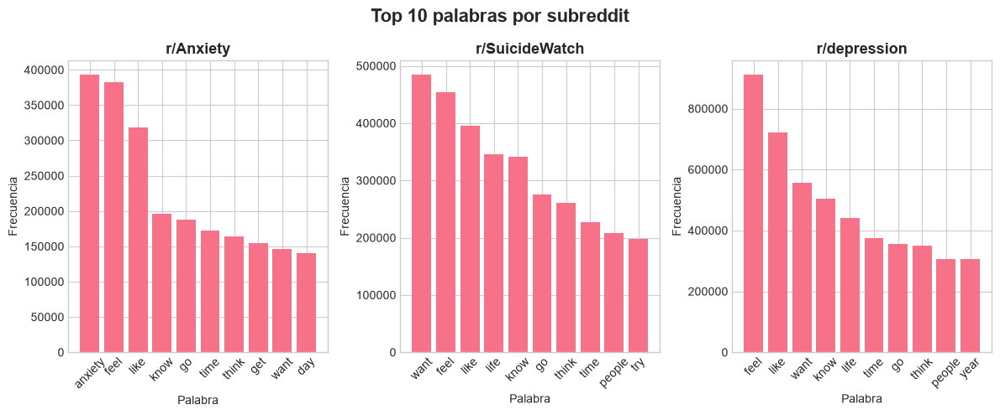

In [97]:
top_words_subreddit = {}
for subreddit in sorted(df_tokens["subreddit"].unique()):
    df_sub = df_tokens[df_tokens["subreddit"] == subreddit]
    freq = get_word_frequencies(df_sub)
    top10 = dict(
        Counter(freq).most_common(10)
    )

    top_words_subreddit[subreddit] = top10

plot_top_words_subreddits(top_words_subreddit, top_n=10)

Para un mayor detalle a nivel temporal, se generan los wordclouds timestrales para cada subreddit 

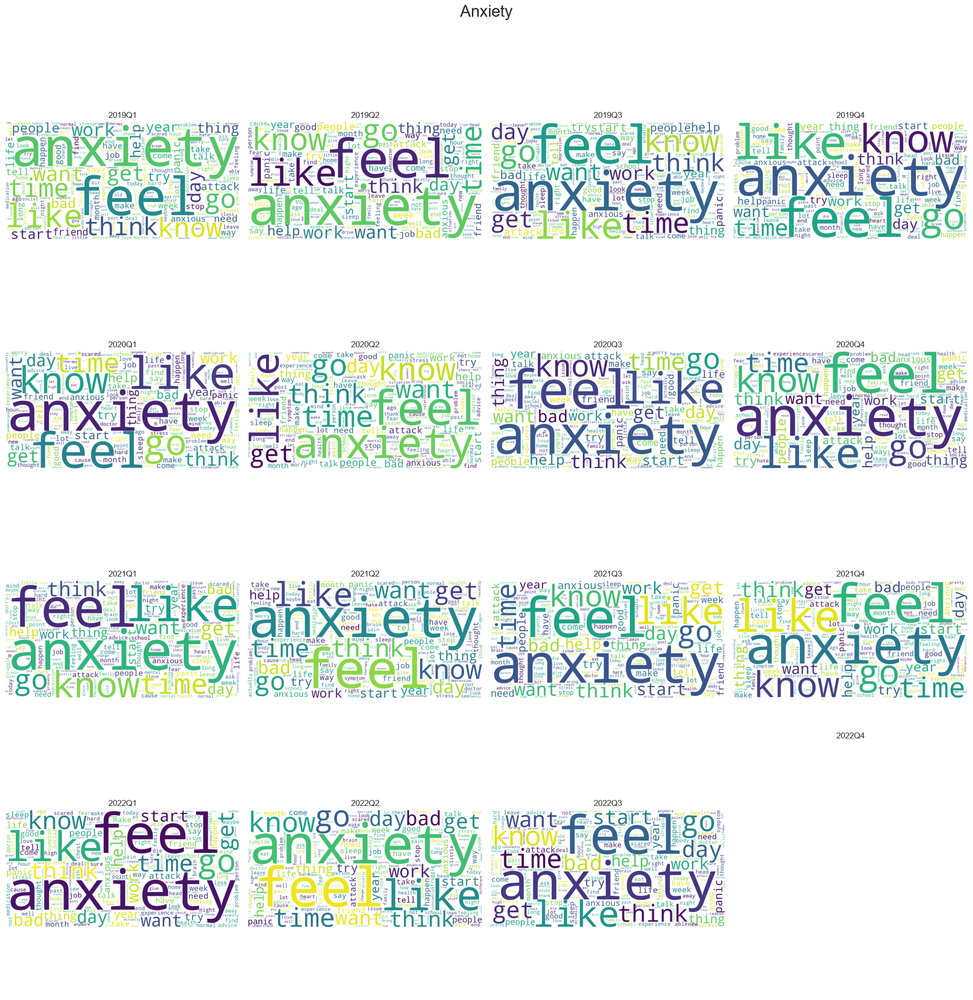

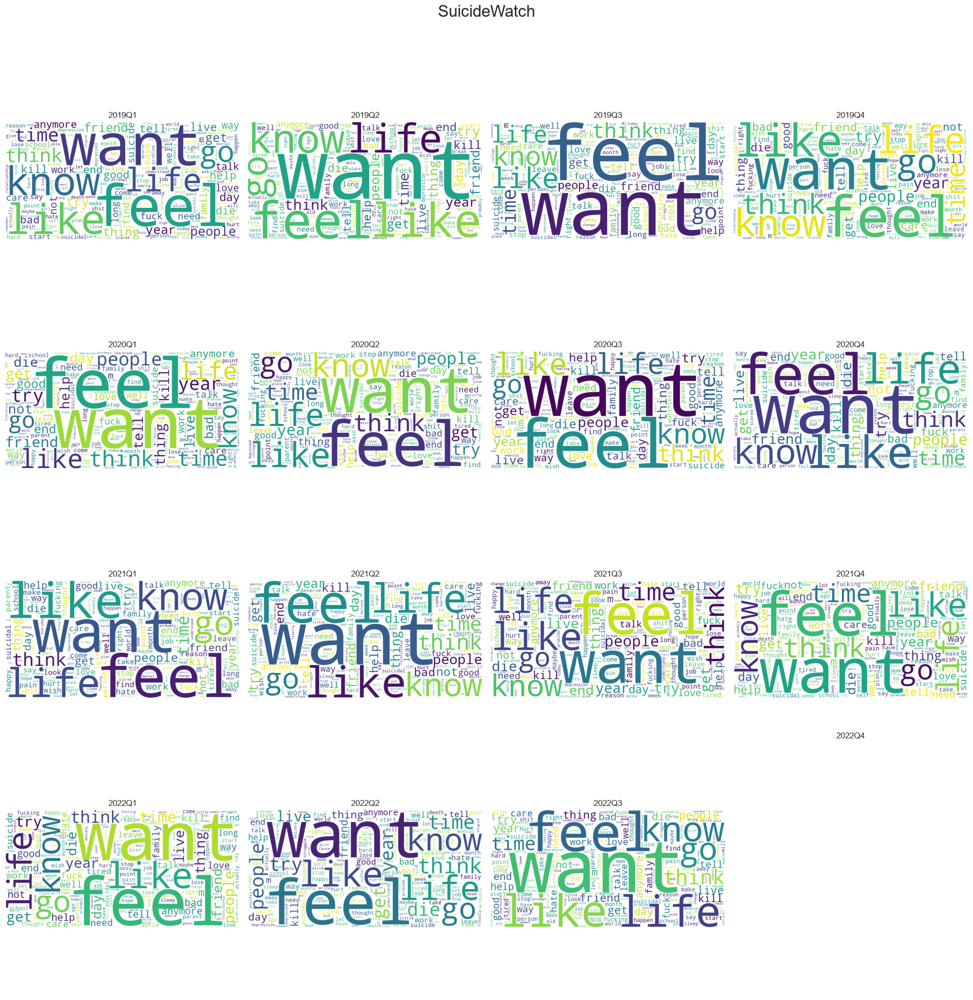

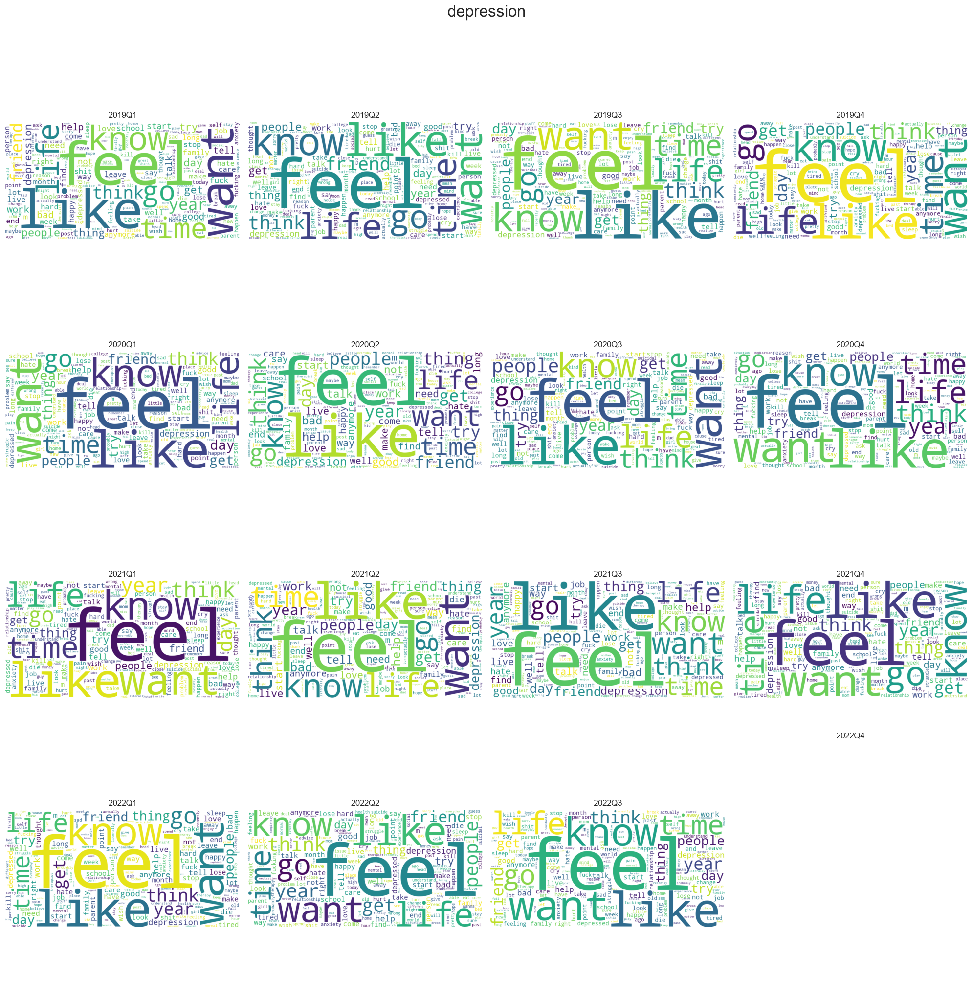

In [101]:
subreddits = sorted(df_tokens["subreddit"].unique())

month_to_num = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4,
    "may": 5, "jun": 6, "jul": 7, "aug": 8,
    "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

for subreddit in subreddits:
    df_sub = df_tokens[df_tokens["subreddit"] == subreddit].copy()

    # Crear trimestre temporalmente, sin modificar df_tokens
    meses = df_sub["month"].str.lower().map(month_to_num)

    trimestres_df = pd.PeriodIndex(
        df_sub["year"].astype(str)
        + "Q"
        + ((meses - 1) // 3 + 1).astype("Int64").astype(str),
        freq="Q"
    )

    df_sub["trimestre"] = trimestres_df

    trimestres = pd.period_range(
        start="2019Q1",
        end="2022Q4",
        freq="Q"
    )

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    axes = axes.flatten()

    for ax, trimestre in zip(axes, trimestres):
        df_trim = df_sub[df_sub["trimestre"] == trimestre]

        if len(df_trim) > 0:
            freq = get_word_frequencies(df_trim)

            if len(freq) > 0:
                wc = WordCloud(
                    width=800,
                    height=400,
                    background_color="white"
                ).generate_from_frequencies(freq)

                ax.imshow(wc)

        ax.set_title(str(trimestre), fontsize=12)
        ax.axis("off")

    fig.suptitle(subreddit, fontsize=24, y=1.02)

    plt.tight_layout()
    plt.show()

Nube de palabras por año 

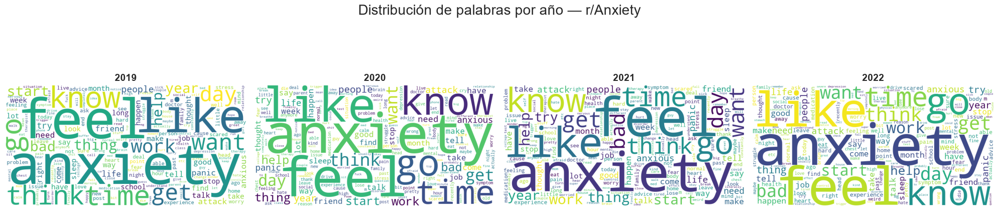

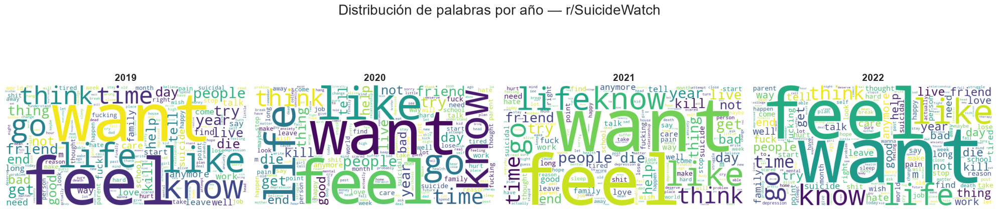

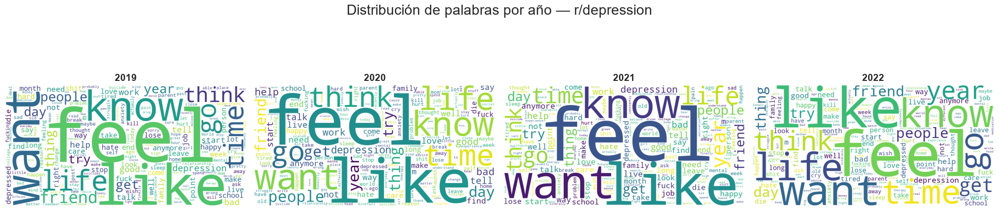

In [102]:
for subreddit in subreddits:
    df_sub = df_tokens[
        df_tokens["subreddit"] == subreddit
    ].copy()

    años = range(2019, 2023)

    fig, axes = plt.subplots(
        1, 4,
        figsize=(20, 5)
    )

    for ax, año in zip(axes, años):
        df_año = df_sub[
            df_sub["year"].astype(int) == año
        ]

        if len(df_año) > 0:
            freq = get_word_frequencies(df_año)

            if len(freq) > 0:
                wc = WordCloud(
                    width=800,
                    height=400,
                    background_color="white"
                ).generate_from_frequencies(freq)

                ax.imshow(wc)

        ax.set_title(
            str(año),
            fontsize=14,
            fontweight="bold"
        )

        ax.axis("off")

    fig.suptitle(
        f"Distribución de palabras por año — r/{subreddit}",
        fontsize=20,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## Bigrams y Skipgrams

Se realiza exploración de los bigramas y skipgramas

In [103]:
def top_ngrams(
    counter,
    top_n=20
):
    '''
    Función para contar los ngramas (ya sean bi o skip)
    '''
    top = pd.DataFrame(
        [
            (
                " ".join(k),
                v
            )
            for k,v
            in counter.most_common(top_n)
        ],
        columns=[
            "ngram",
            "freq"
        ]
    )

    return top

Para visualizar los ngramas, se genera un grafo que permite identificar palabras que están más cerca a otras de acuerdo con la frecuencia con que aparecen juntas

In [104]:
def build_graph(
    counter,
    min_freq=8000
):
    G = nx.Graph()
    for (
        w1,
        w2
    ), count in counter.items():
        if count >= min_freq:
            G.add_edge(
                w1,
                w2,
                weight=count
            )
    return G

def plot_graph(
    G,
    title=""
):
    pos = nx.spring_layout(
        G,
        seed=42,
        k=2.5,
        iterations=300
    )

    # Edges
    edge_traces = []

    for u, v in G.edges():
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        weight = G[u][v].get("weight", 1)
        edge_trace = go.Scatter(
            x=[x0, x1, None],
            y=[y0, y1, None],
            mode="lines",
            line=dict(
                width=weight / 3,
            ),
            hoverinfo="none"
        )

        edge_traces.append(edge_trace)

    # Nodes
    node_x = []
    node_y = []
    node_text = []

    for node in G.nodes():
        x, y = pos[node]

        node_x.append(x)
        node_y.append(y)
        node_text.append(str(node))

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode="markers+text",
        text=node_text,
        textposition="top center",
        hovertext=node_text,
        hoverinfo="text",
        marker=dict(
            size=12,
            line=dict(width=1)
        )
    )

    fig = go.Figure(
        data=edge_traces + [node_trace]
    )

    fig.update_layout(
        title=title,
        showlegend=False,
        hovermode="closest",
        margin=dict(
            l=20,
            r=20,
            t=50,
            b=20
        ),
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        height=900,
        width=900
    )

    fig.show()

### Skipgrams

Los **skip-grams** son una extensión de los **n-gramas** que permiten omitir hasta `k` palabras entre los términos.

```python
skipgrams(tokens, n, k)
```

- `tokens`: lista de palabras.
- `n`: tamaño del n-grama.
- `k`: máximo número de palabras que se pueden omitir.

**Ejemplo**

```python
tokens = ["el", "gato", "negro", "duerme"]
```

Con `skipgrams(tokens, 2, 0)`:

```text
(el, gato)
(gato, negro)
(negro, duerme)
```

Con `skipgrams(tokens, 2, 1)`:

```text
(el, gato)
(el, negro)
(gato, negro)
(gato, duerme)
(negro, duerme)
```

Permiten capturar relaciones entre palabras que no necesariamente son consecutivas.

In [105]:
def build_skipgram_counter(df):
    counter = Counter()
    for tokens in df["tokens"]:
        sg = skipgrams(
            tokens,
            2,
            1
        )
        counter.update(sg)
    return counter

In [106]:
G_skipgrams_subreddits = dict()

for sr in subreddits:
    df_sr = df_tokens[df_tokens["subreddit"]==sr]

    skips = build_skipgram_counter(df_sr)

    print(
            f"\nTOP SKIPGRAMAS {sr}"
        )

    print(
            top_ngrams(skips)
        )

    G_skip = build_graph(
            skips
        )

    plot_graph(
            G_skip,
            title=f"{sr} Skipgram Graph"
        )
    G_skipgrams_subreddits[sr] = G_skip


TOP SKIPGRAMAS Anxiety
                 ngram    freq
0            feel like  138007
1         panic attack   61933
2       anxiety attack   21844
3              get bad   17363
4         feel anxious   16908
5         anxiety feel   16681
6          anxiety bad   15998
7                go to   15329
8              like go   14673
9          bad anxiety   13381
10       mental health   13381
11            year ago   13031
12           make feel   12834
13           feel feel   12798
14      social anxiety   12685
15           like feel   12327
16            feel bad   12134
17         anxiety get   12000
18  anxiety depression   11515
19     anxiety anxiety   11054



TOP SKIPGRAMAS SuicideWatch
               ngram    freq
0          feel like  167209
1           want die   58279
2          want want   39973
3              go to   37789
4          want kill   23564
5          want live   22311
6           year old   22212
7            get bad   21834
8   suicidal thought   21506
9          want feel   21456
10          want end   21345
11      want anymore   19666
12          not know   19217
13       good friend   19124
14         feel feel   19057
15          not want   18994
16          end life   18344
17         hate hate   18331
18         know want   18004
19    commit suicide   17864



TOP SKIPGRAMAS depression
            ngram    freq
0       feel like  333440
1       want want   43484
2       feel feel   42511
3        want die   35800
4       know feel   34741
5           go to   34567
6        feel bad   33834
7       want feel   33552
8         get bad   32170
9       like feel   31513
10       year old   31377
11    good friend   31071
12  mental health   30973
13       year ago   28532
14      make feel   28453
15      feel well   27764
16      time feel   27212
17       not know   27194
18      life feel   26947
19    high school   24985


### Bigramas

In [107]:
def build_bigram_counter(df):
    counter = Counter()
    for tokens in df["tokens"]:
        counter.update(
            ngrams(tokens, 2)
        )

    return counter

In [108]:
G_bigrams_subreddits = dict()
for sr in subreddits:
    df_sr = df_tokens[df_tokens["subreddit"]==sr]
    bigrams = build_bigram_counter(df_sr)

    print(
            f"\nTOP BIGRAMAS {sr}"
        )

    print(
            top_ngrams(bigrams)
        )

    G_bigram = build_graph(
            bigrams
        )

    plot_graph(
            G_bigram,
            title=f"{sr} Bigram Graph"
        )
    G_bigrams_subreddits[sr] = G_bigram


TOP BIGRAMAS Anxiety
                 ngram    freq
0            feel like  130490
1         panic attack   60956
2       anxiety attack   16821
3                go to   15267
4              get bad   14329
5        mental health   13156
6             year ago   12381
7         feel anxious   12216
8       social anxiety   12014
9            make feel   11208
10            year old   10555
11             like go    9877
12           month ago    9855
13  anxiety depression    9778
14            feel bad    9296
15         bad anxiety    9217
16      health anxiety    9102
17           feel well    8457
18         anxiety bad    8446
19          start feel    7904



TOP BIGRAMAS SuicideWatch
               ngram    freq
0          feel like  159826
1           want die   52880
2              go to   37595
3           year old   21733
4   suicidal thought   20978
5          want kill   20959
6          want live   18655
7            get bad   17872
8        good friend   17708
9     commit suicide   17697
10          not know   17524
11     mental health   17296
12          want end   17086
13          year ago   16567
14          not want   16022
15          end life   15916
16          feel bad   14115
17          get well   13726
18         need help   13113
19       high school   12877



TOP BIGRAMAS depression
                 ngram    freq
0            feel like  316012
1                go to   34397
2             want die   33182
3        mental health   30594
4             year old   30594
5          good friend   28320
6             feel bad   27384
7             year ago   27348
8              get bad   26588
9             not know   25216
10           make feel   25095
11         high school   24751
12           feel well   21892
13            feel way   20322
14           long time   18941
15           know feel   18060
16           need help   17693
17           want feel   17604
18  depression anxiety   17058
19            get well   16900


### Métricas

A partir de las redes construidas, se extraen métricas que dan una idea de la forma como se organizan los ngramas en el texto

In [109]:
def network_metrics(G):
    metrics = {}
    metrics["nodes"] = (
        G.number_of_nodes()
    )
    metrics["edges"] = (
        G.number_of_edges()
    )
    metrics["density"] = (
        nx.density(G)
    )
    metrics["transitivity"] = (
        nx.transitivity(G)
    )
    degrees = [
        d
        for _,d
        in G.degree()
    ]
    metrics["avg_degree"] = (
        np.mean(degrees)
    )
    comps = list(
        nx.connected_components(G)
    )
    giant = max(
        comps,
        key=len
    )
    metrics[
        "giant_component_fraction"
    ] = (
        len(giant)
        /
        G.number_of_nodes()
    )

    return metrics

In [110]:
for sr in subreddits:
    G_bigram = G_bigrams_subreddits[sr]
    G_skip = G_skipgrams_subreddits[sr]

    metrics_bigram = (
            network_metrics(
                G_bigram
            )
        )

    metrics_skip = (
            network_metrics(
                G_skip
            )
        )

    metrics_df = pd.DataFrame(
            [
                metrics_bigram,
                metrics_skip
            ],
            index=[
                "bigram",
                "skipgram"
            ]
        )
    
    print("-"*20,sr,"-"*20)
    display(metrics_df)

-------------------- Anxiety --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,20,18,0.094737,0.000000,1.8000,0.8
skipgram,32,43,0.086694,0.150685,2.6875,1.0


-------------------- SuicideWatch --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,44,43,0.045455,0.181034,1.954545,0.500000
skipgram,58,94,0.056866,0.259740,3.241379,0.724138


-------------------- depression --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,70,83,0.034369,0.138817,2.371429,0.614286
skipgram,91,199,0.048596,0.290625,4.373626,0.791209


In [111]:
def centralities(G):
    deg = nx.degree_centrality(G)
    bet = nx.betweenness_centrality(
        G
    )
    eig = nx.eigenvector_centrality(
        G,
        max_iter=1000
    )
    deg_df = (
        pd.DataFrame(
            deg.items(),
            columns=[
                "word",
                "degree"
            ]
        )
        .sort_values(
            "degree",
            ascending=False
        )
    )

    bet_df = (
        pd.DataFrame(
            bet.items(),
            columns=[
                "word",
                "betweenness"
            ]
        )
        .sort_values(
            "betweenness",
            ascending=False
        )
    )

    return (
        deg_df,
        bet_df
    )

In [113]:
for sr in subreddits:
    print("-"*20,sr,"-"*20)
    G_bigram = G_bigrams_subreddits[sr]
    (
        degree_df_bigram,
        betweenness_df_bigram
    ) = centralities(
        G_bigram
    ) 

    print("BIGRAM")
    print("TOP DEGREE")
    display(degree_df_bigram)
    print("TOP BETWEENNESS")
    display(betweenness_df_bigram)

    G_skip = G_skipgrams_subreddits[sr]
    (
        degree_df_skipgram,
        betweenness_df_skipgram
    ) = centralities(
        G_skip
    ) 

    print("SKIPGRAM")
    print("TOP DEGREE")
    display(degree_df_skipgram)
    print("TOP BETWEENNESS")
    display(betweenness_df_skipgram)

-------------------- Anxiety --------------------
BIGRAM
TOP DEGREE


,word,degree
11,anxiety,0.263158
6,feel,0.263158
9,bad,0.157895
1,attack,0.105263
7,like,0.105263
5,ago,0.105263
2,go,0.105263
4,year,0.105263
15,health,0.105263
0,panic,0.052632


TOP BETWEENNESS


,word,betweenness
11,anxiety,0.391813
6,feel,0.385965
9,bad,0.368421
7,like,0.152047
15,health,0.081871
1,attack,0.081871
2,go,0.081871
4,year,0.011696
5,ago,0.011696
0,panic,0.000000


SKIPGRAM
TOP DEGREE


...

,word,betweenness
0,feel,0.267827
5,want,0.072464
1,like,0.067186
17,good,0.064578
28,time,0.048806
...,...,...
65,home,0.000000
66,suicidal,0.000000
67,thought,0.000000
68,sad,0.000000


SKIPGRAM
TOP DEGREE


,word,degree
0,feel,0.466667
1,like,0.333333
11,want,0.266667
5,know,0.211111
13,life,0.188889
...,...,...
83,thought,0.011111
86,depressed,0.011111
87,struggle,0.011111
88,stop,0.011111


TOP BETWEENNESS


,word,betweenness
0,feel,0.285086
1,like,0.136562
25,year,0.086477
11,want,0.079212
6,depression,0.068839
...,...,...
86,depressed,0.000000
87,struggle,0.000000
88,stop,0.000000
89,worthless,0.000000


### NPMI

La información mutua puntual (PMI) mide cuánto más probable es que dos palabras aparezcan juntas de lo que esperaríamos si fueran independientes.

${PMI}(x,y)=\log\left(\frac{P(x,y)}{P(x)P(y)}\right)$

In [ ]:
top_n = 7

def calcular_npmi_pares(df_sub, top_n=7):
    # Cada comentario es un documento con palabras únicas
    documentos = [
        set(texto)
        for texto in df_sub["tokens"]
        if isinstance(texto, (list, tuple)) and len(texto) > 0
    ]

    N = len(documentos)

    if N == 0:
        return pd.DataFrame(columns=["par", "npmi"])

    # Frecuencia de palabras y de coocurrencias
    frecuencia = Counter()
    coocurrencia = Counter()

    for doc in documentos:
        frecuencia.update(doc)
        coocurrencia.update(combinations(sorted(doc), 2))

    # Seleccionar las palabras más frecuentes
    palabras_top = {
        palabra for palabra, _ in frecuencia.most_common(top_n * 3)
    }

    resultados = []

    for (w1, w2), n_cooc in coocurrencia.items():
        if w1 not in palabras_top or w2 not in palabras_top:
            continue

        p_xy = n_cooc / N
        p_x = frecuencia[w1] / N
        p_y = frecuencia[w2] / N

        if p_xy <= 0 or p_xy >= 1:
            continue

        pmi = math.log(p_xy / (p_x * p_y))
        npmi = pmi / (-math.log(p_xy))

        resultados.append({
            "par": f"{w1} {w2}",
            "npmi": npmi,
            "frecuencia": n_cooc
        })

    return (
        pd.DataFrame(resultados)
        .sort_values("npmi", ascending=False)
        .head(top_n)
    )


# Ajusta "tokens" si tu columna de palabras tokenizadas tiene otro nombre
fig, axes = plt.subplots(
    len(subreddits), 1,
    figsize=(14, 2.8 * len(subreddits))
)

for ax, subreddit in zip(axes, subreddits):
    df_sub = df_tokens[df_tokens["subreddit"] == subreddit]

    resultados = calcular_npmi_pares(df_sub, top_n=top_n)

    if resultados.empty:
        ax.set_title(subreddit, loc="left", fontweight="bold")
        ax.text(0.5, 0.5, "Sin pares disponibles", ha="center")
        continue

    resultados = resultados.sort_values("npmi", ascending=True)

    barras = ax.barh(
        resultados["par"],
        resultados["npmi"],
        color="#e77d96"
    )

    ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=9)
    ax.set_title(subreddit, loc="left", fontweight="bold")
    ax.set_xlabel("NPMI promedio")
    ax.set_ylabel("Par de palabras")
    ax.set_xlim(0, 1.05)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Embeddings

Dada la complejidad del lenguaje en Reddit (sarcasmo, polisemias, abreviaciones, extranjerismos), los embeddings requieren enfoques más complejos que permitan captar el contexto y el contenido. Por tal motivo, se utiliza BAAI, un modelo entrenado y enfocado en inglés que, publicado en 2024, estableció un estado del arte, garantizando calidad ante comentarios variados.

https://arxiv.org/abs/2402.03216

In [ ]:
def compute_embeddings(
    texts,
    model_name='BAAI/bge-small-en-v1.5',
    cache_path=None,
    batch_size=64,
    chunk_size=2000,          # cuántos textos procesar antes de guardar
    local_model_dir=None,
    force_recompute=False,
):
    cache_path = Path(cache_path) if cache_path else None
    tmp_dir = cache_path.with_suffix('') if cache_path else Path('embeddings_tmp')
    tmp_dir = Path(str(tmp_dir) + '_chunks')

    # 1. Si ya existe el archivo final, no recalcules nada
    if cache_path and cache_path.exists() and not force_recompute:
        print(f"✅ Cargando embeddings desde caché: {cache_path}")
        return np.load(cache_path)

    # 2. Usar todos los núcleos disponibles
    n_threads = os.cpu_count()
    torch.set_num_threads(n_threads)
    print(f"🧵 Usando {n_threads} hilos de CPU")

    # 3. Modo offline (usa el modelo ya descargado, sin tocar internet)
    os.environ.setdefault("HF_HUB_OFFLINE", "1")
    os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

    print(f"🔄 Calculando embeddings con {model_name}...")
    model_path = local_model_dir if local_model_dir else model_name
    model = SentenceTransformer(model_path, device="cpu")
    model.max_seq_length = 512

    # 4. Preparar carpeta de bloques (checkpoints)
    tmp_dir.mkdir(parents=True, exist_ok=True)
    n_texts = len(texts)
    n_chunks = (n_texts + chunk_size - 1) // chunk_size

    if force_recompute:
        # Borra bloques viejos si se pide recalcular desde cero
        for f in tmp_dir.glob("chunk_*.npy"):
            f.unlink()

    # 5. Procesar bloque por bloque, saltando los que ya existen
    for i in range(n_chunks):
        chunk_file = tmp_dir / f"chunk_{i:05d}.npy"
        if chunk_file.exists():
            print(f"⏭️  Bloque {i+1}/{n_chunks} ya existe, saltando...")
            continue

        start = i * chunk_size
        end = min(start + chunk_size, n_texts)
        chunk_texts = texts[start:end]

        print(f"🔹 Bloque {i+1}/{n_chunks} (textos {start}-{end})...")
        chunk_embeddings = model.encode(
            chunk_texts,
            batch_size=batch_size,
            convert_to_numpy=True,
            show_progress_bar=True,
            normalize_embeddings=True,
        )

        # Guardado atómico: escribe a un .tmp y luego renombra,
        # así un corte de luz a mitad de escritura no deja el bloque corrupto
        tmp_file = chunk_file.with_suffix('.tmp.npy')
        np.save(tmp_file, chunk_embeddings)
        os.replace(tmp_file, chunk_file)
        print(f"💾 Bloque {i+1}/{n_chunks} guardado en {chunk_file}")

    # 6. Unir todos los bloques en el array final
    print("🔗 Uniendo bloques...")
    all_chunks = [np.load(tmp_dir / f"chunk_{i:05d}.npy") for i in range(n_chunks)]
    embeddings = np.concatenate(all_chunks, axis=0)

    # 7. Guardar el resultado final y limpiar bloques temporales
    if cache_path:
        np.save(cache_path, embeddings)
        print(f"💾 Embeddings finales guardados en {cache_path}")
        for f in tmp_dir.glob("chunk_*.npy"):
            f.unlink()
        tmp_dir.rmdir()

    return embeddings


embeddings = compute_embeddings(
    df['text_clean'].tolist(),
#    model_name='BAAI/bge-small-en-v1.5',
    model_name = "all-MiniLM-L6-v2",
    cache_path=r'..\Datasets\Embeddings\embeddings_allmini.npy',
    chunk_size=10000,   # ajusta según cuántos textos tengas (ver nota abajo)
)

df['embedding_idx'] = range(len(df))
np.save("embeddings.npy", embeddings)

print(f"\n Embeddings shape: {embeddings.shape}")
print(f"   Dimensión por post: {embeddings.shape[1]}")
print(f"   Memoria aproximada: {embeddings.nbytes / 1e6:.1f} MB")

Se hace uso de Embedkit para analizar las métricas del embedding creado, permitiendo reducir dimensionalidad, mejorar su calidad y garantizar representaciones precisas.

Dado que la librería realiza el análisis a partir de la selección el hiperparámetro k, se prueban con varios valores

In [ ]:
for i in [10,20,30,40,50]:
    print("===================",i,"===================")
    report = EmbedKitAnalyzer(k=i).fit(embeddings)  
    report.print_summary()

Hay alta consistencia de las salidas de las métricas en los análisis de diferentes k (Dimensión Intrínseca = 32) para un dimensión sugerida de 48

Se refinan los embeddings usando UMAP

In [ ]:
def reduce_embeddings(emb_matrix, n_components=2, muestra=1.0, random_state=42):
    """
    Entrena UMAP sobre una muestra de emb_matrix y transforma todo el conjunto.
    """
    n = emb_matrix.shape[0]

    reducer = umap.UMAP(
        n_components=n_components,
        n_neighbors=5,
        metric="cosine",
        low_memory=True,
        n_jobs=1,
        random_state=random_state
    )

    if muestra < 1.0:
        rng = np.random.default_rng(random_state)
        n_sample = max(int(n * muestra), n_components + 2)  
        idx = rng.choice(n, size=n_sample, replace=False)
        reducer.fit(emb_matrix[idx])
    else:
        reducer.fit(emb_matrix)

    return reducer.transform(emb_matrix)


X_refined = reduce_embeddings(embeddings, n_components=42, muestra=0.4)

In [ ]:
X_refined_embedkit = EmbedKit(epochs=20, batch_size = 512, eval_every=1, early_stopping_patience=5).fit_transform(embeddings)

Nuevamente se realiza análisis sobre las dimensiones reducidas

In [ ]:
for i in [10,20,30,40,50]:
    print("===================",i,"===================")
    report = EmbedKitAnalyzer(k=i).fit(X_refined_embedkit)  
    report.print_summary()

# Atributos del grafo

Para la construcción del grafo, se define su estructura, los atributos de los nodos, los criterios de conexión y las variables relevantes para su visualización y posterior análisis temporal.

**Estructura global del grafo:** El grafo se construye de manera que cada nodo represente un comentario de Reddit y las aristas establezcan relaciones semánticas entre ellos, permitiendo identificar agrupaciones temáticas y analizar patrones en las conversaciones sobre salud mental.

Para ello, se establecen los siguientes elementos:

- **Embeddings:** representaciones vectoriales de los comentarios que permiten cuantificar su similitud semántica y establecer los criterios de conexión entre nodos mediante las aristas.
- **Subreddit:** atributo de cada nodo que identifica la comunidad de Reddit de la que proviene el comentario, lo que permite analizar las relaciones entre comunidades de salud mental.
- **Año y mes:** atributos temporales que registran la fecha de publicación de cada comentario y permite estudiar la evolución del grafo a lo largo del tiempo.

Adicionalmente, el grafo incorpora atributos derivados del modelado de emociones y del modelado de tópicos mediante BERTopic, que permiten caracterizar los comentarios según sus patrones emocionales y temáticos. Estos atributos sirven como base para análisis complementarios y para explorar la evolución temporal de las conversaciones.